In [1]:
import sys; sys.path.append('..')
from pyspark.sql import SparkSession, functions as F
from src.eda import load, null_report

spark = SparkSession.builder.appName('home-credit').getOrCreate()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/08 09:57:43 WARN Utils: Your hostname, Hungs-MacBook-Pro.local, resolves to a loopback address: 127.0.0.1; using 192.168.31.211 instead (on interface en0)
26/10/08 09:57:43 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/08 09:57:43 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/08 09:57:44 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/10/08 09:57:45 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


# Data Overview


In [ ]:
import os
app = load('application_train')
print('Số dòng:', app.count())
print('Số SK_ID_CURR:', app.select('SK_ID_CURR').distinct().count())
os.makedirs('../outputs', exist_ok=True)
rep = null_report(app)
rep.to_csv('../outputs/null_report_application_train.csv', index=False)
rep

## application_train — Tổng quan
- 307,511 dòng, 122 cột. 1 dòng = 1 đơn vay hiện tại, định danh bằng `SK_ID_CURR`.
- Nhãn `TARGET`: 1 = khách gặp khó khăn trả nợ, 0 = không.
- Đây là bảng trung tâm: mọi bảng khác đều phải gộp về 1 dòng / `SK_ID_CURR` rồi ghép vào bảng này.

## Các nhóm cột
- **Định danh & nhãn**: `SK_ID_CURR`, `TARGET`.
- **Khoản vay hiện tại**: loại hợp đồng (`NAME_CONTRACT_TYPE`), số tiền vay (`AMT_CREDIT`),
  tiền trả mỗi kỳ (`AMT_ANNUITY`), giá hàng hóa mua bằng khoản vay (`AMT_GOODS_PRICE`).
- **Nhân khẩu**: giới tính, tuổi (`DAYS_BIRTH`), số con, số người trong gia đình,
  tình trạng hôn nhân, học vấn.
- **Thu nhập & công việc**: tổng thu nhập, loại thu nhập, nghề nghiệp, loại tổ chức làm việc,
  thời gian đi làm (`DAYS_EMPLOYED`).
- **Tài sản**: có xe không, tuổi xe, có nhà không, hình thức nhà ở.
- **Thông tin tòa nhà nơi ở**: 47 cột (diện tích, số tầng, thang máy, năm xây…),
  mỗi chỉ số có 3 bản `_AVG`, `_MODE`, `_MEDI`.
- **Khu vực**: mật độ dân số vùng, xếp hạng vùng, 6 cờ địa chỉ đăng ký / nơi sống / nơi làm
  có khác vùng, khác thành phố không.
- **Liên lạc**: các cờ có điện thoại di động, điện thoại công ty, email…,
  số ngày từ lần đổi điện thoại gần nhất.
- **Hồ sơ nộp đơn**: ai đi cùng khi nộp, thứ và giờ nộp đơn, số ngày từ lúc đăng ký / làm giấy tờ,
  20 cờ `FLAG_DOCUMENT_*` (có nộp giấy tờ số X không).
- **Điểm chấm từ nguồn ngoài**: `EXT_SOURCE_1/2/3`, thang 0–1, đề không nói nguồn nào.
- **Vòng quen biết**: 4 cột `*_SOCIAL_CIRCLE`, số người quen từng trễ hạn 30 / 60 ngày.
- **Số lần bị tra cứu tín dụng**: 6 cột `AMT_REQ_CREDIT_BUREAU_*`,
  theo giờ / ngày / tuần / tháng / quý / năm trước khi nộp đơn.
- Các cột `DAYS_*` là số ngày tính ngược từ ngày nộp đơn (giá trị âm).

## Chất lượng dữ liệu
- 67/122 cột có null, 55 cột không null.
- **Thông tin tòa nhà nơi ở** là nguồn null lớn nhất: 47 cột, null 47–70%.
  Cao nhất là `COMMONAREA_*` (69.9%), thấp nhất là `EMERGENCYSTATE_MODE` (47.4%).
  3 bản `_AVG/_MODE/_MEDI` của cùng một chỉ số có số null y hệt nhau,
  tức là thực chất 1 thông tin bị lặp 3 lần.
- **Tài sản**: `OWN_CAR_AGE` null 66%.
- **Điểm nguồn ngoài**: mức thiếu rất khác nhau giữa 3 nguồn,
  `EXT_SOURCE_1` 56%, `EXT_SOURCE_3` 20%, `EXT_SOURCE_2` chỉ 0.2%.
- **Nghề nghiệp**: `OCCUPATION_TYPE` null 31%.
- **Tra cứu tín dụng**: 6 cột `AMT_REQ_CREDIT_BUREAU_*` cùng null 13.5% (41,519 dòng),
  tức là trống cùng một nhóm đơn.
- **Vòng quen biết**: 4 cột `*_SOCIAL_CIRCLE` cùng null 0.33% (1,021 dòng).
- **Null lác đác** (dưới 0.5%): `NAME_TYPE_SUITE` 1,292 dòng, `AMT_GOODS_PRICE` 278,
  `AMT_ANNUITY` 12, `CNT_FAM_MEMBERS` 2, `DAYS_LAST_PHONE_CHANGE` 1.

## Kết luận chất lượng dữ liệu
- **Null tập trung gần như hoàn toàn ở thông tin cá nhân chi tiết, khó thu thập**:
  đặc điểm tòa nhà nơi ở (47 cột, null 47–70%), tuổi xe (66%), nghề nghiệp (31%),
  điểm chấm từ nguồn ngoài (`EXT_SOURCE_1` 56%, `EXT_SOURCE_3` 20%).
  Đây là những thông tin khách không bắt buộc khai, hoặc phụ thuộc nguồn bên ngoài.
- **Thông tin khoản vay hiện tại đầy đủ**: số tiền vay, tiền trả mỗi kỳ,
  giá hàng hóa, loại hợp đồng gần như 0 null (chỉ lác đác vài trăm dòng).
- **Thông tin cá nhân cơ bản đầy đủ**: tuổi, giới tính, thu nhập, học vấn, gia đình,
  loại nhà ở, khu vực, liên lạc, giấy tờ đều 0 null.
- **Nhãn `TARGET` đầy đủ**, không có dòng nào thiếu.
- → Phần lõi để dự đoán (khoản vay + thông tin cơ bản) sạch. Rủi ro dữ liệu nằm ở nhóm
  thông tin phụ, trong đó đáng lưu ý nhất là `EXT_SOURCE_1/3` vì thiếu nhiều.

# Phân Tích Đơn Biến

In [17]:
def target_rate(df, col):
    total = df.count()
    result = df.groupBy(col).agg(
        F.count('*').alias('n'),
        F.sum('TARGET').alias('n_1'),
        F.avg('TARGET').alias('rate'),
    )
    rows = result.orderBy(col).collect()

    names = []
    pct_0 = []
    pct_1 = []

    for r in rows:
        share = round(r['n'] / total * 100, 2)
        rate = round(r['rate'] * 100, 2)
        print(r[col], '| số đơn:', r['n'], '| % tổng:', share,
              '| số đơn khó khăn chi trả:', r['n_1'], '| % khó khăn chi trả:', rate)

        names.append(str(r[col]))
        pct_1.append(r['rate'] * 100)
        pct_0.append(100 - r['rate'] * 100)

    plt.bar(names, pct_0, label='0')
    plt.bar(names, pct_1, bottom=pct_0, label='1')
    plt.ylabel('Percentage')
    plt.xlabel(col)
    plt.title(f'Tỷ lệ khó khăn chi trả theo {col}')
    plt.legend(title='TARGET')
    plt.show()

Cash loans | số đơn: 278232 | % tổng: 90.48 | số đơn khó khăn chi trả: 23221 | % khó khăn chi trả: 8.35
Revolving loans | số đơn: 29279 | % tổng: 9.52 | số đơn khó khăn chi trả: 1604 | % khó khăn chi trả: 5.48


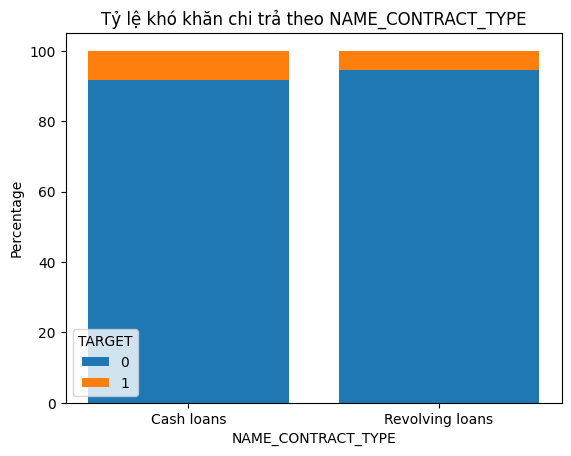

In [18]:
target_rate(app, 'NAME_CONTRACT_TYPE')

- Các koản vay cũ thì có đa phần là các khoản vay tiền mặt, chiếm 90%, còn 10% còn lại đến từ các phương pháp khác như hạn mức xoay vòng.
- Trong 278232 khoản vay cũ, tỉ lệ 8.35% khách hàng có khó khăn trong việc chi trả, k dc xét duyệt khoản vay, còn với khách sử dụng phương pháp khác, có khoảng 5% khách có khó khăn trong việc chi trả


F | số đơn: 202448 | % tổng: 65.83 | số đơn khó khăn chi trả: 14170 | % khó khăn chi trả: 7.0
M | số đơn: 105059 | % tổng: 34.16 | số đơn khó khăn chi trả: 10655 | % khó khăn chi trả: 10.14
XNA | số đơn: 4 | % tổng: 0.0 | số đơn khó khăn chi trả: 0 | % khó khăn chi trả: 0.0


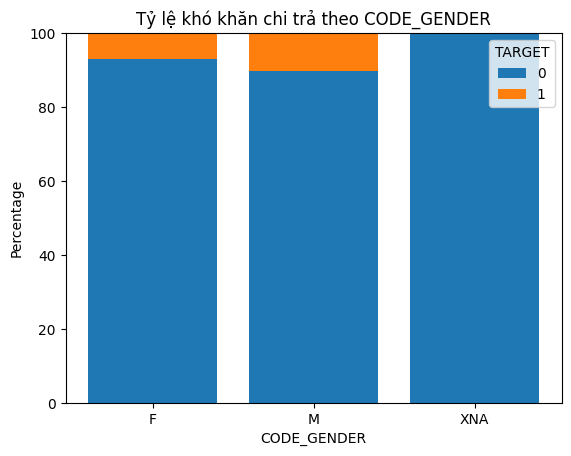

In [19]:
target_rate(app,'CODE_GENDER')

- Nữ chiếm 66% tổng số khoản vay (202,448 khoản), nam chiếm 34% (105,059 khoản). XNA chỉ 4 khoản, không đáng kể.
- Xét về tỷ lệ khó khăn trong việc chi trả, nam có tỷ lệ 10.14%, cao hơn rõ so với 7.0% của nữ (gấp ~1.45 lần), đây là điều cần được chú ý vì số lượng khách hàng ít hơn 30%

0 | số đơn: 215371 | % tổng: 70.04 | số đơn khó khăn chi trả: 16609 | % khó khăn chi trả: 7.71
1 | số đơn: 61119 | % tổng: 19.88 | số đơn khó khăn chi trả: 5454 | % khó khăn chi trả: 8.92
2 | số đơn: 26749 | % tổng: 8.7 | số đơn khó khăn chi trả: 2333 | % khó khăn chi trả: 8.72
3+ | số đơn: 4272 | % tổng: 1.39 | số đơn khó khăn chi trả: 429 | % khó khăn chi trả: 10.04


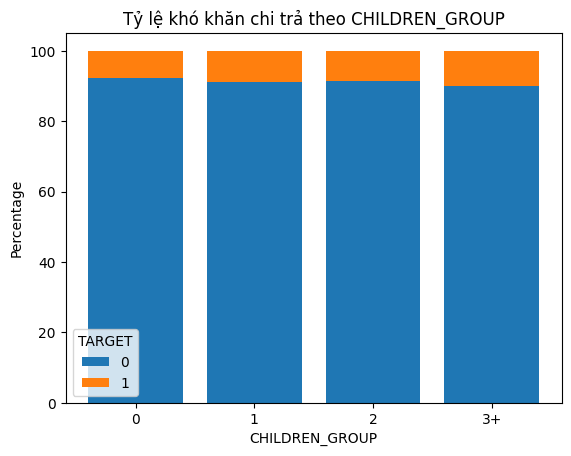

In [20]:
app = app.withColumn(
    'CHILDREN_GROUP',
    F.when(F.col('CNT_CHILDREN') == 0, '0')
     .when(F.col('CNT_CHILDREN') == 1, '1')
     .when(F.col('CNT_CHILDREN') == 2, '2')
     .otherwise('3+')
)
target_rate(app, 'CHILDREN_GROUP')

- 70% các khoản vay đến từ khách hàng chưa có con, 20% từ khách có 1 con, khách có từ 2 con trở lên chỉ chiếm khoảng 10%.
- Khách có con có tỷ lệ khó khăn chi trả cao hơn khách chưa có con (8.7–8.9% so với 7.71%), nhóm từ 3 con trở lên cao nhất với 10.04% nhưng số lượng ít (4,272 khoản). Mức chênh lệch không lớn, số con là tín hiệu yếu nhưng có thể phản ánh áp lực tài chính gia đình, nên xét kết hợp với thu nhập.

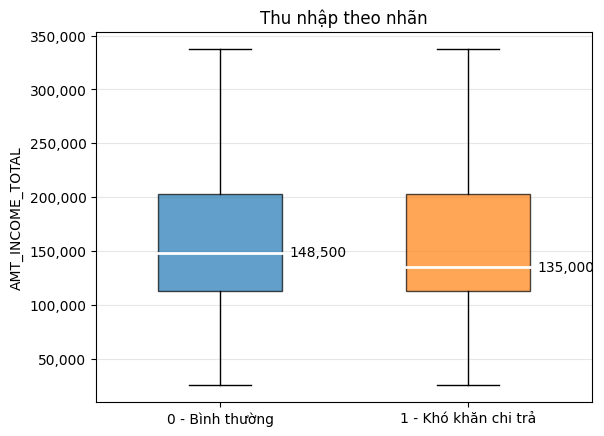

In [22]:
box = plt.boxplot([income_0, income_1], showfliers=False, patch_artist=True, widths=0.5)

colors = ['tab:blue', 'tab:orange']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

for median in box['medians']:
    median.set_color('white')
    median.set_linewidth(2)

# ghi giá trị trung vị lên hình
for i, data in enumerate([income_0, income_1]):
    med = sorted(data)[len(data) // 2]
    plt.text(i + 1.28, med, f'{med:,.0f}', va='center')

plt.xticks([1, 2], ['0 - Bình thường', '1 - Khó khăn chi trả'])
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.grid(axis='y', alpha=0.3)
plt.ylabel('AMT_INCOME_TOTAL')
plt.title('Thu nhập theo nhãn')
plt.show()

- Phân bố thu nhập giữa hai nhóm gần như trùng nhau: 50% khách nằm trong khoảng 112,500 – 202,500, phần râu trên dưới cũng tương đương.
- Nhóm khó khăn chi trả có trung vị thu nhập thấp hơn nhẹ (135,000 so với 148,500, thấp hơn ~9%), nhưng mức chênh nhỏ so với độ trải của dữ liệu.
- Thu nhập đứng riêng là tín hiệu yếu để phân biệt khách khó khăn chi trả. Cần xét thu nhập so với khoản vay (khoản vay gấp bao nhiêu lần thu nhập, tiền trả mỗi kỳ chiếm bao nhiêu % thu nhập) ở bước làm feature.

In [23]:
def boxplot_by_target(df, col):
    data = []
    for label in [0, 1]:
        rows = df.filter((F.col('TARGET') == label) & F.col(col).isNotNull()).select(col).collect()
        data.append([r[col] for r in rows])

    box = plt.boxplot(data, showfliers=False, patch_artist=True, widths=0.5)

    colors = ['tab:blue', 'tab:orange']
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    for median in box['medians']:
        median.set_color('white')
        median.set_linewidth(2)

    for i, values in enumerate(data):
        med = sorted(values)[len(values) // 2]
        plt.text(i + 1.28, med, f'{med:,.0f}', va='center')

    plt.xticks([1, 2], ['0 - Bình thường', '1 - Khó khăn chi trả'])
    plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
    plt.grid(axis='y', alpha=0.3)
    plt.ylabel(col)
    plt.title(f'{col} theo nhãn')
    plt.show()

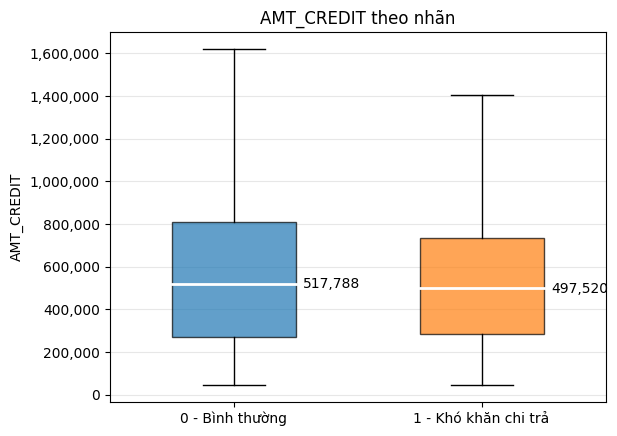

In [24]:
boxplot_by_target(app, 'AMT_CREDIT')

- Trung vị số tiền vay hai nhóm gần nhau: 517,788 (bình thường) so với 497,520 (khó khăn chi trả).
- Nhóm khó khăn chi trả có hộp thấp hơn ở phía trên: Q3 khoảng 735k so với 810k của nhóm bình thường, cận trên cũng thấp hơn (~1.4 triệu so với ~1.6 triệu). Tức là các khoản vay rất lớn xuất hiện ít hơn ở nhóm khó khăn chi trả.

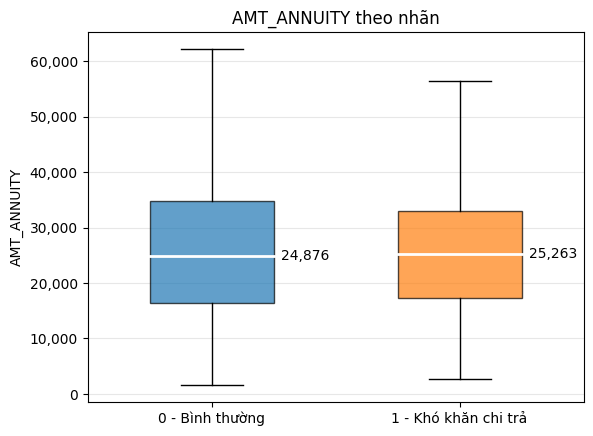

In [25]:
boxplot_by_target(app, 'AMT_ANNUITY')

- Trung vị tiền trả mỗi kỳ hai nhóm gần như bằng nhau: 24,876 (bình thường) so với 25,263 (khó khăn chi trả).
- Nhóm khó khăn chi trả tập trung hơn: 50% khoản nằm trong ~17k – 33k, so với ~16.5k – 35k ở nhóm bình thường; cận trên thấp hơn (~56k so với ~62k)

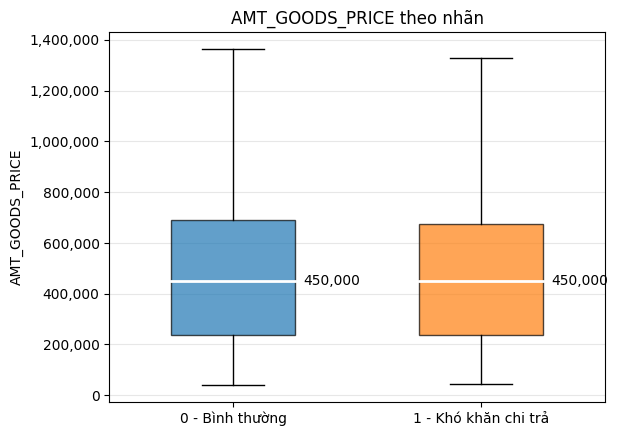

In [26]:
boxplot_by_target(app, 'AMT_GOODS_PRICE')

- Giá món hàng hai nhóm gần như trùng khít: trung vị đều 450,000, hộp đều khoảng 238k – 680k, cận trên chênh không đáng kể (1.36 triệu so với 1.33 triệu).
- Trung vị đúng tròn 450,000 ở cả hai nhóm cho thấy giá hàng tập trung ở các mức tròn, kiểu gói vay / mức giá phổ biến.

In [29]:
app = app.withColumn('AGE_YEARS', F.col('DAYS_BIRTH') / -365)
app = app.withColumn('REGISTRATION_YEARS', F.col('DAYS_REGISTRATION') / -365)

app = app.withColumn('EMPLOYED_YEARS', F.when(F.col('DAYS_EMPLOYED') != 365243, F.col('DAYS_EMPLOYED') / -365))
app = app.withColumn('EMPLOYED_365243', F.when(F.col('DAYS_EMPLOYED') == 365243, 'Yes').otherwise('No'))

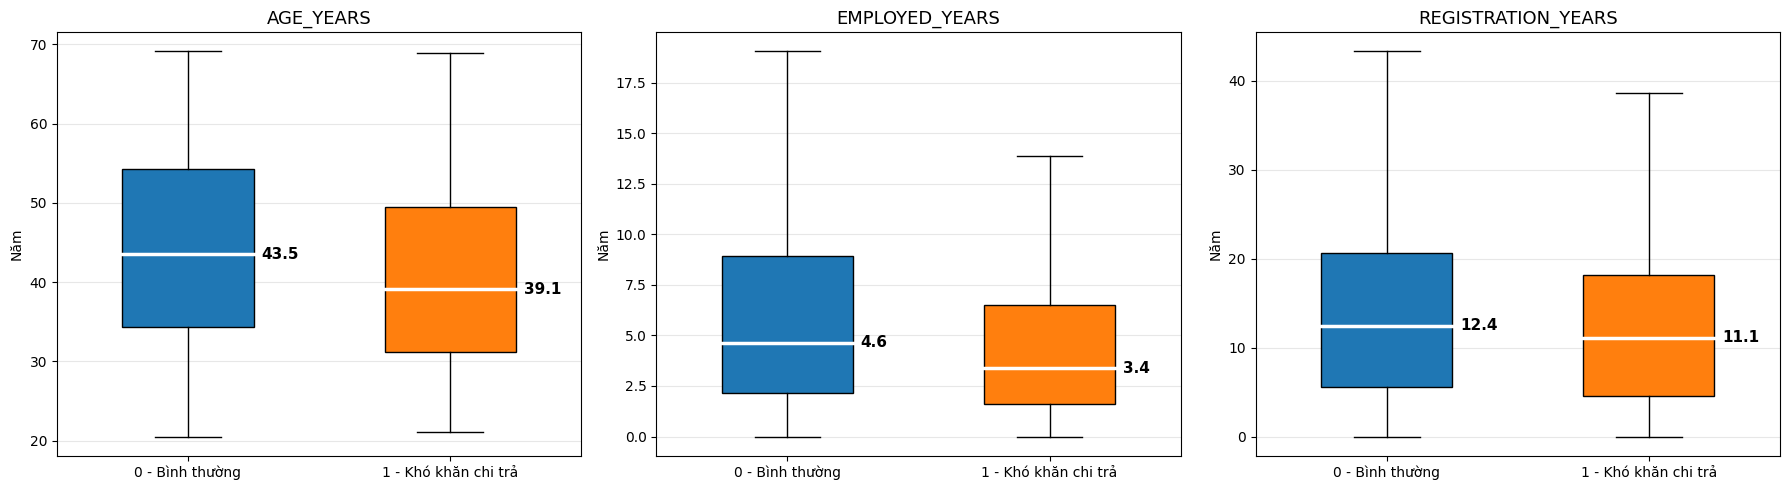

In [33]:
cols = ['AGE_YEARS', 'EMPLOYED_YEARS', 'REGISTRATION_YEARS']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(cols):
    data = []
    for label in [0, 1]:
        rows = app.filter((F.col('TARGET') == label) & F.col(col).isNotNull()).select(col).collect()
        data.append([r[col] for r in rows])

    box = axes[i].boxplot(data, showfliers=False, patch_artist=True, widths=0.5)
    box['boxes'][0].set_facecolor('tab:blue')
    box['boxes'][1].set_facecolor('tab:orange')

    for median in box['medians']:
        median.set_color('white')
        median.set_linewidth(2.5)

    for j, values in enumerate(data):
        med = sorted(values)[len(values) // 2]
        axes[i].text(j + 1.28, med, f'{med:.1f}', va='center', fontsize=11, fontweight='bold')

    axes[i].set_xticks([1, 2])
    axes[i].set_xticklabels(['0 - Bình thường', '1 - Khó khăn chi trả'])
    axes[i].set_title(col, fontsize=13)
    axes[i].set_ylabel('Năm')
    axes[i].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

- Tuổi (AGE_YEARS): khác biệt rõ nhất. Nhóm khó khăn chi trả trẻ hơn, trung vị 39.1 tuổi so với 43.5; cả hộp cũng dịch xuống (31–49 so với 34–54). Khách càng trẻ càng dễ gặp khó khăn chi trả.
- Số năm đi làm (EMPLOYED_YEARS): nhóm khó khăn chi trả đi làm ngắn hơn, trung vị 3.4 năm so với 4.6; hộp thấp hơn (1.6–6.5 so với 2.1–8.9), cận trên cũng thấp hơn hẳn (14 so với 19 năm). Thâm niên công việc thấp, thu nhập kém ổn định đi kèm rủi ro cao hơn. (Chưa tính nhóm mã 365243, xem riêng.)
- Số năm từ lần đổi đăng ký (REGISTRATION_YEARS): chênh lệch nhỏ, trung vị 11.1 so với 12.4, hai hộp chồng lên nhau gần hết. Tín hiệu yếu.
So với nhóm cột tiền (thu nhập, khoản vay, giá hàng) gần như không phân biệt được, thì tuổi và thâm niên đi làm là tín hiệu rõ hơn: khách trẻ, mới đi làm là nhóm cần chú ý.

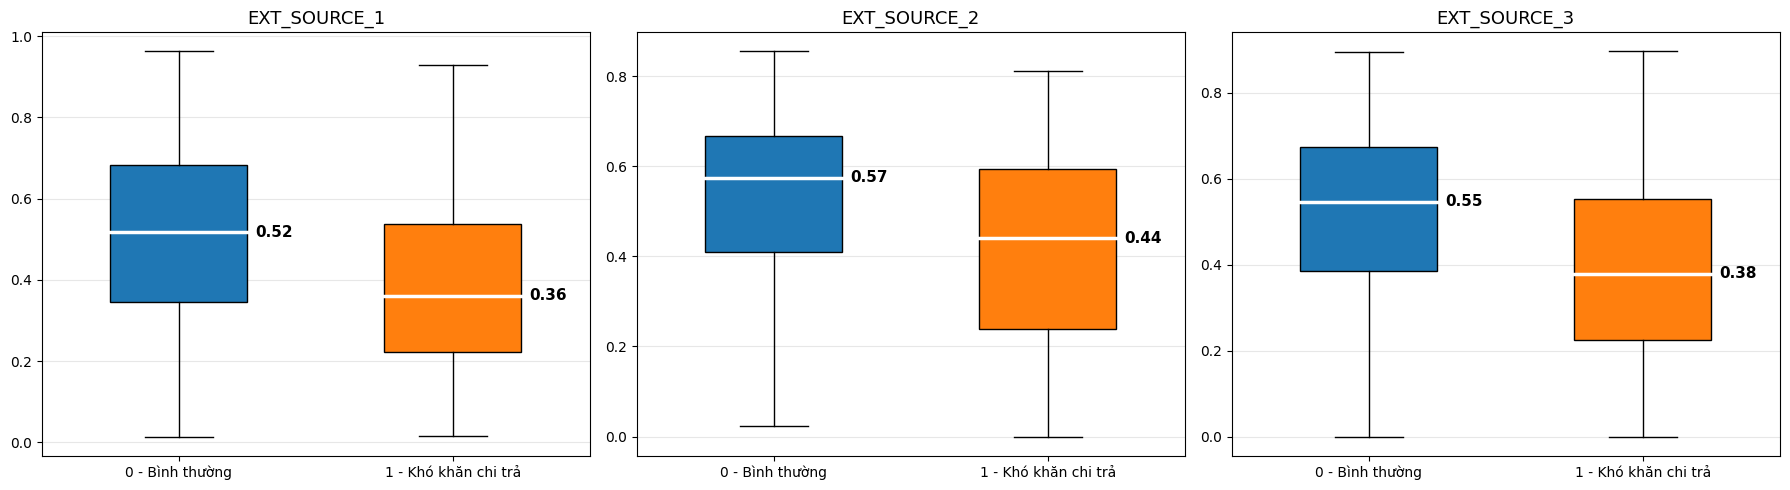

In [45]:
cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(cols):
    data = []
    for label in [0, 1]:
        rows = app.filter((F.col('TARGET') == label) & F.col(col).isNotNull()).select(col).collect()
        data.append([r[col] for r in rows])

    box = axes[i].boxplot(data, showfliers=False, patch_artist=True, widths=0.5)
    box['boxes'][0].set_facecolor('tab:blue')
    box['boxes'][1].set_facecolor('tab:orange')

    for median in box['medians']:
        median.set_color('white')
        median.set_linewidth(2.5)

    for j, values in enumerate(data):
        med = sorted(values)[len(values) // 2]
        axes[i].text(j + 1.28, med, f'{med:.2f}', va='center', fontsize=11, fontweight='bold')

    axes[i].set_xticks([1, 2])
    axes[i].set_xticklabels(['0 - Bình thường', '1 - Khó khăn chi trả'])
    axes[i].set_title(col, fontsize=13)
    axes[i].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

- EXT_SOURCE_1: trung vị nhóm bình thường 0.52, nhóm khó khăn chi trả 0.36, lệch 0.16. Hộp nhóm khó khăn (khoảng 0.22–0.54) tụt xuống so với nhóm bình thường (khoảng 0.35–0.68), đỉnh hộp cam chỉ ngang đường trung vị hộp xanh.
- EXT_SOURCE_2: trung vị 0.57 so với 0.44, lệch 0.13, ít nhất trong 3 nguồn. Hộp nhóm khó khăn trải rộng hơn hẳn (khoảng 0.24–0.59 so với 0.41–0.67), tức là điểm của khách khó khăn chi trả rất phân tán, có cả người điểm khá cao.
- EXT_SOURCE_3: trung vị 0.55 so với 0.38, lệch 0.17, nhiều nhất trong 3 nguồn. Đỉnh hộp cam (0.55) đúng bằng trung vị hộp xanh: 3/4 khách khó khăn chi trả có điểm thấp hơn một nửa số khách bình thường.
So sánh 3 nguồn: EXT_SOURCE_3 và EXT_SOURCE_1 tách hai nhóm rõ nhất nhưng thiếu nhiều (20% và 56%); EXT_SOURCE_2 tách kém hơn chút nhưng gần như khách nào cũng có điểm (chỉ thiếu 0.2%)

# Phân tích Đa Biến

1. Có phải khách hàng cao tuổi và đi làm lâu năm sẽ có ít rủi ro tín dụng hơn không ?

In [34]:
# chỉ lấy người có số năm đi làm thật (bỏ mã 365243)
df2 = app.filter(F.col('EMPLOYED_YEARS').isNotNull())

df2 = df2.withColumn('AGE_GROUP',
    F.when(F.col('AGE_YEARS') < 30, '20-30')
     .when(F.col('AGE_YEARS') < 40, '30-40')
     .when(F.col('AGE_YEARS') < 50, '40-50')
     .otherwise('50+'))

df2 = df2.withColumn('EMP_GROUP',
    F.when(F.col('EMPLOYED_YEARS') < 1, '<1')
     .when(F.col('EMPLOYED_YEARS') < 3, '1-3')
     .when(F.col('EMPLOYED_YEARS') < 5, '3-5')
     .when(F.col('EMPLOYED_YEARS') < 10, '5-10')
     .otherwise('10+'))

rows = df2.groupBy('AGE_GROUP', 'EMP_GROUP').agg(
    F.count('*').alias('n'), F.avg('TARGET').alias('rate')).collect()

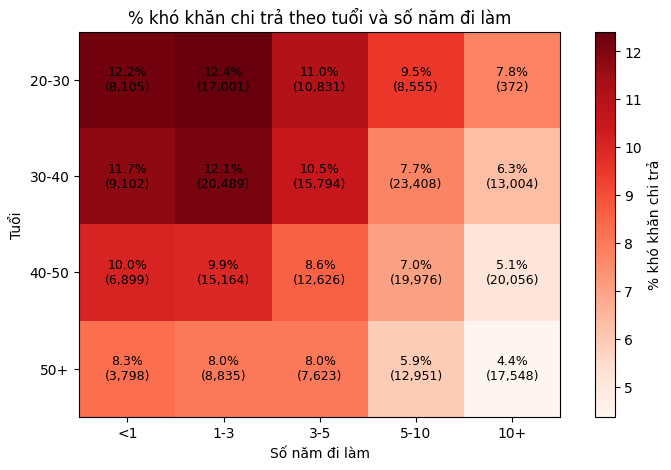

In [37]:
age_groups = ['20-30', '30-40', '40-50', '50+']
emp_groups = ['<1', '1-3', '3-5', '5-10', '10+']

# cất kết quả vào dict: (tuổi, năm làm) -> (tỷ lệ, số đơn)
cell = {}
for r in rows:
    cell[(r['AGE_GROUP'], r['EMP_GROUP'])] = (r['rate'] * 100, r['n'])

matrix = []
for a in age_groups:
    line = []
    for e in emp_groups:
        if (a, e) in cell:
            line.append(cell[(a, e)][0])
        else:
            line.append(float('nan'))
    matrix.append(line)

plt.figure(figsize=(9, 5))
plt.imshow(matrix, cmap='Reds')
plt.colorbar(label='% khó khăn chi trả')

for i, a in enumerate(age_groups):
    for j, e in enumerate(emp_groups):
        if (a, e) in cell:
            rate, n = cell[(a, e)]
            plt.text(j, i, f'{rate:.1f}%\n({n:,})', ha='center', va='center', fontsize=9)

plt.xticks(range(len(emp_groups)), emp_groups)
plt.yticks(range(len(age_groups)), age_groups)
plt.xlabel('Số năm đi làm')
plt.ylabel('Tuổi')
plt.title('% khó khăn chi trả theo tuổi và số năm đi làm')
plt.show()

- Ở mỗi nhóm tuổi, khách hàng càng đi làm lâu thì tỷ lệ khó khăn chi trả càng giảm. Ví dụ nhóm 40–50 tuổi: mới đi làm dưới 1 năm là 10.0%, đi làm trên 10 năm chỉ còn 5.1%.
- Cùng số năm đi làm, khách trên 40 tuổi có tỷ lệ khó khăn chi trả thấp hơn khách dưới 40, kể cả khi mới đi làm dưới 1 năm (8.3–10.0% so với 11.7–12.2%). Nhóm trên 50 tuổi thấp nhất ở mọi mức thâm niên.
- Hai yếu tố cộng dồn: khách trẻ và mới đi làm (~12%) có tỷ lệ khó khăn chi trả cao gấp ~2.8 lần khách trên 50 tuổi và đi làm trên 10 năm (4.4%).

2. Có phải khách hàng nam hay gặp khó khăn hơn chi trả hơn khách nữ khi tuổi cao hơn ?

In [38]:
app = app.withColumn('AGE_GROUP',
    F.when(F.col('AGE_YEARS') < 30, '20-30')
     .when(F.col('AGE_YEARS') < 40, '30-40')
     .when(F.col('AGE_YEARS') < 50, '40-50')
     .otherwise('50+'))

rows = (app.filter(F.col('CODE_GENDER') != 'XNA')
           .groupBy('CODE_GENDER', 'AGE_GROUP')
           .agg(F.count('*').alias('n'), F.avg('TARGET').alias('rate'))
           .collect())

# cất kết quả: (giới tính, nhóm tuổi) -> (tỷ lệ, số đơn)
cell = {}
for r in rows:
    cell[(r['CODE_GENDER'], r['AGE_GROUP'])] = (r['rate'] * 100, r['n'])

M 20-30 | số đơn: 19463 | % khó khăn chi trả: 12.55
M 30-40 | số đơn: 32192 | % khó khăn chi trả: 10.95
M 40-50 | số đơn: 26950 | % khó khăn chi trả: 9.44
M 50+ | số đơn: 26454 | % khó khăn chi trả: 8.11
F 20-30 | số đơn: 25535 | % khó khăn chi trả: 10.62
F 30-40 | số đơn: 50106 | % khó khăn chi trả: 8.7
F 40-50 | số đơn: 49593 | % khó khăn chi trả: 6.69
F 50+ | số đơn: 77214 | % khó khăn chi trả: 4.89


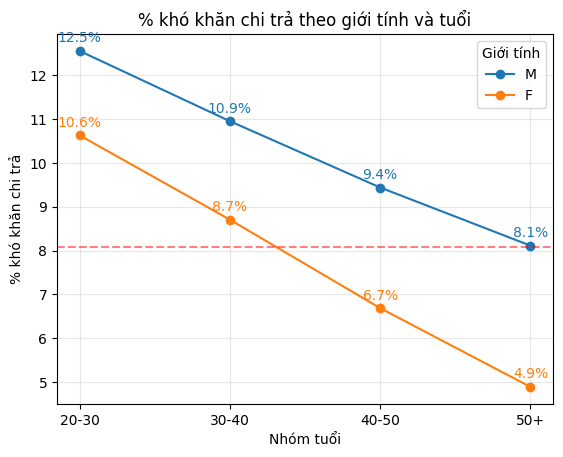

In [39]:
age_groups = ['20-30', '30-40', '40-50', '50+']

for gender, color in [('M', 'tab:blue'), ('F', 'tab:orange')]:
    rates = []
    for a in age_groups:
        rate, n = cell[(gender, a)]
        rates.append(rate)
        print(gender, a, '| số đơn:', n, '| % khó khăn chi trả:', round(rate, 2))

    plt.plot(age_groups, rates, marker='o', color=color, label=gender)
    for x, y in zip(age_groups, rates):
        plt.text(x, y + 0.2, f'{y:.1f}%', ha='center', color=color)

plt.axhline(8.07, color='red', linestyle='--', alpha=0.5)
plt.xlabel('Nhóm tuổi')
plt.ylabel('% khó khăn chi trả')
plt.title('% khó khăn chi trả theo giới tính và tuổi')
plt.legend(title='Giới tính')
plt.grid(alpha=0.3)
plt.show()

- Nam luôn rủi ro hơn nữ ở mọi độ tuổi: đường nam nằm trên đường nữ từ đầu đến cuối. Tức là chênh lệch giới tính không phải chỉ do nam trẻ hơn, mà có thật.
- Tuổi càng cao, khoảng cách nam nữ càng doãng ra: 20–30 tuổi nam cao hơn nữ 1.9 % (12.5% vs 10.6%), đến 50+ cao hơn 3.2  (8.1% vs 4.9%). Nữ giảm rủi ro theo tuổi nhanh hơn nam.
- Nam 50+ (8.1%) rủi ro ngang nữ 30–40 tuổi (8.7%): nam phải lớn hơn nữ khoảng 15–20 tuổi mới về được cùng mức rủi ro.

3. Thu nhập và thâm niên có ảnh hưởng gì tới việc chi trả của Khách hàng ?

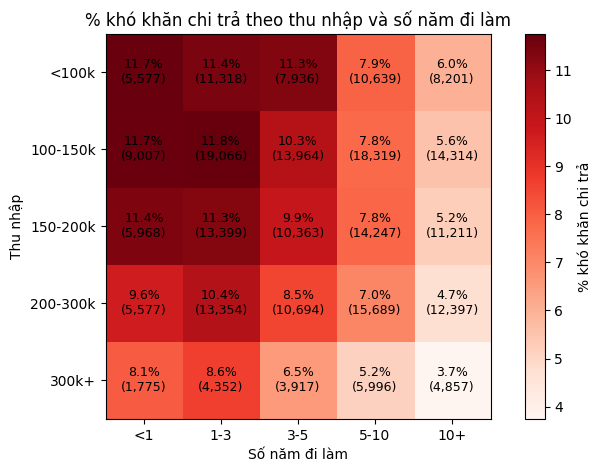

In [40]:
app = app.withColumn('INCOME_GROUP',
    F.when(F.col('AMT_INCOME_TOTAL') < 100000, '<100k')
     .when(F.col('AMT_INCOME_TOTAL') < 150000, '100-150k')
     .when(F.col('AMT_INCOME_TOTAL') < 200000, '150-200k')
     .when(F.col('AMT_INCOME_TOTAL') < 300000, '200-300k')
     .otherwise('300k+'))

app = app.withColumn('EMP_GROUP',
    F.when(F.col('EMPLOYED_YEARS') < 1, '<1')
     .when(F.col('EMPLOYED_YEARS') < 3, '1-3')
     .when(F.col('EMPLOYED_YEARS') < 5, '3-5')
     .when(F.col('EMPLOYED_YEARS') < 10, '5-10')
     .otherwise('10+'))

# bỏ mã 365243 (EMPLOYED_YEARS null)
rows = (app.filter(F.col('EMPLOYED_YEARS').isNotNull())
           .groupBy('INCOME_GROUP', 'EMP_GROUP')
           .agg(F.count('*').alias('n'), F.avg('TARGET').alias('rate'))
           .collect())

cell = {}
for r in rows:
    cell[(r['INCOME_GROUP'], r['EMP_GROUP'])] = (r['rate'] * 100, r['n'])

income_groups = ['<100k', '100-150k', '150-200k', '200-300k', '300k+']
emp_groups = ['<1', '1-3', '3-5', '5-10', '10+']

matrix = []
for inc in income_groups:
    line = []
    for e in emp_groups:
        if (inc, e) in cell:
            line.append(cell[(inc, e)][0])
        else:
            line.append(float('nan'))
    matrix.append(line)

plt.figure(figsize=(9, 5))
plt.imshow(matrix, cmap='Reds')
plt.colorbar(label='% khó khăn chi trả')

for i, inc in enumerate(income_groups):
    for j, e in enumerate(emp_groups):
        if (inc, e) in cell:
            rate, n = cell[(inc, e)]
            plt.text(j, i, f'{rate:.1f}%\n({n:,})', ha='center', va='center', fontsize=9)

plt.xticks(range(len(emp_groups)), emp_groups)
plt.yticks(range(len(income_groups)), income_groups)
plt.xlabel('Số năm đi làm')
plt.ylabel('Thu nhập')
plt.title('% khó khăn chi trả theo thu nhập và số năm đi làm')
plt.show()

- Ở mọi mức thu nhập, đi làm càng lâu càng ít rủi ro. Hàng nào cũng giảm dần từ trái sang phải. Ví dụ thu nhập dưới 100k: mới đi làm dưới 1 năm là 11.7%, đi làm trên 10 năm còn 6.0%; thu nhập trên 300k: 8.1% xuống 3.7%.
- Thu nhập dưới 200k thì cao thấp không khác gì nhau. Cùng mới đi làm dưới 1 năm, người thu nhập dưới 100k hay 150–200k thì cứ 100 người vẫn có khoảng 11–12 người gặp khó khăn chi trả. Phải từ 200k trở lên, và rõ nhất là trên 300k, tỷ lệ mới giảm xuống.
- Thâm niên quan trọng hơn thu nhập. Cùng mức thu nhập, người đi làm trên 10 năm có tỷ lệ khó khăn chi trả chỉ bằng một nửa người mới đi làm. Còn cùng thâm niên, tăng thu nhập từ dưới 100k lên trên 300k chỉ giảm được khoảng một phần ba (ví dụ mới đi làm dưới 1 năm: 11.7% xuống 8.1%).
- Hai yếu tố cộng dồn: thu nhập dưới 100k và mới đi làm dưới 1 năm là 11.7%, gấp 3.2 lần nhóm thu nhập trên 300k và đi làm trên 10 năm (3.7%).

→ Trả lời câu hỏi: đúng, thu nhập cao và đi làm lâu ít rủi ro hơn, nhưng thu nhập chỉ tạo khác biệt khi vượt mức 200k, còn thâm niên thì tác động ở mọi mức thu nhập.

3. Ở cùng mức thu nhập, có phải việc có con sẽ làm gia tăng tỉ lệ khó khăn trong việc chi trả ?

0 con | <100k | số đơn: 46204 | % khó khăn chi trả: 7.53
0 con | 100-150k | số đơn: 64479 | % khó khăn chi trả: 8.17
0 con | 150-200k | số đơn: 44703 | % khó khăn chi trả: 8.19
0 con | 200-300k | số đơn: 44871 | % khó khăn chi trả: 7.37
0 con | 300k+ | số đơn: 15114 | % khó khăn chi trả: 5.9
1 con | <100k | số đơn: 11207 | % khó khăn chi trả: 9.82
1 con | 100-150k | số đơn: 18082 | % khó khăn chi trả: 9.98
1 con | 150-200k | số đơn: 13117 | % khó khăn chi trả: 8.91
1 con | 200-300k | số đơn: 13703 | % khó khăn chi trả: 7.98
1 con | 300k+ | số đơn: 5010 | % khó khăn chi trả: 5.73
2+ con | <100k | số đơn: 6287 | % khó khăn chi trả: 10.23
2+ con | 100-150k | số đơn: 9030 | % khó khăn chi trả: 9.08
2+ con | 150-200k | số đơn: 6487 | % khó khăn chi trả: 9.3
2+ con | 200-300k | số đơn: 6602 | % khó khăn chi trả: 7.91
2+ con | 300k+ | số đơn: 2615 | % khó khăn chi trả: 6.65


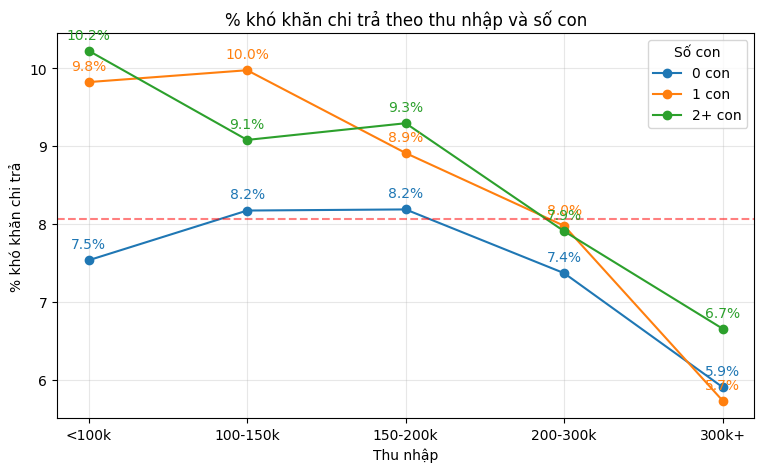

In [42]:
app = app.withColumn('CHILD_GROUP',
    F.when(F.col('CNT_CHILDREN') == 0, '0')
     .when(F.col('CNT_CHILDREN') == 1, '1')
     .otherwise('2+'))

rows = (app.groupBy('CHILD_GROUP', 'INCOME_GROUP')
           .agg(F.count('*').alias('n'), F.avg('TARGET').alias('rate'))
           .collect())

cell = {}
for r in rows:
    cell[(r['CHILD_GROUP'], r['INCOME_GROUP'])] = (r['rate'] * 100, r['n'])

income_groups = ['<100k', '100-150k', '150-200k', '200-300k', '300k+']

plt.figure(figsize=(9, 5))

for child, color in [('0', 'tab:blue'), ('1', 'tab:orange'), ('2+', 'tab:green')]:
    rates = []
    for inc in income_groups:
        rate, n = cell[(child, inc)]
        rates.append(rate)
        print(child, 'con |', inc, '| số đơn:', n, '| % khó khăn chi trả:', round(rate, 2))

    plt.plot(income_groups, rates, marker='o', color=color, label=f'{child} con')
    for x, y in zip(income_groups, rates):
        plt.text(x, y + 0.15, f'{y:.1f}%', ha='center', color=color)

plt.axhline(8.07, color='red', linestyle='--', alpha=0.5)
plt.xlabel('Thu nhập')
plt.ylabel('% khó khăn chi trả')
plt.title('% khó khăn chi trả theo thu nhập và số con')
plt.legend(title='Số con')
plt.grid(alpha=0.3)
plt.show()

- Thu nhập dưới 200k, có con rủi ro hơn rõ. Cùng mức thu nhập dưới 100k, cứ 100 người không con có 7.5 người gặp khó khăn chi trả, còn người có con là 9.8–10.2 người. Ở 3 mức thu nhập dưới 200k, đường có con luôn nằm trên đường không con.
- Thu nhập từ 200k trở lên, số con gần như không còn khác biệt. Ở mức 200–300k ba đường gần chụm lại (7.4–8.0%), trên 300k người có 1 con (5.7%) còn thấp hơn người không con (5.9%). Chỉ nhóm 2 con trở lên vẫn nhỉnh hơn (6.7%).
- Thu nhập giúp giảm rủi ro nhiều nhất với người có con. Người có 1 con giảm từ 9.8% (dưới 100k) xuống 5.7% (trên 300k), còn người không con gần như đi ngang ở mức 7.5–8.2% cho đến khi thu nhập trên 200k.

4. Thu nhập có ảnh hưởng tới các khoản vay không ?

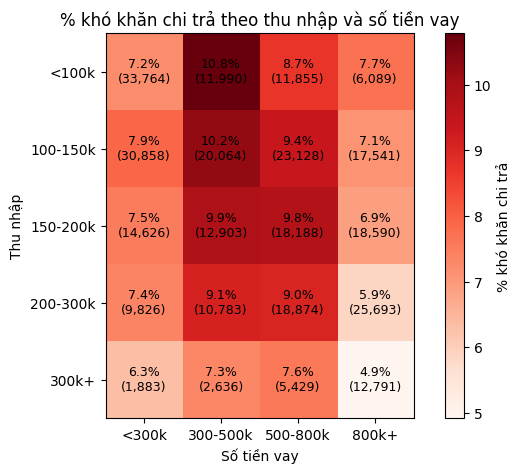

In [43]:
app = app.withColumn('CREDIT_GROUP',
    F.when(F.col('AMT_CREDIT') < 300000, '<300k')
     .when(F.col('AMT_CREDIT') < 500000, '300-500k')
     .when(F.col('AMT_CREDIT') < 800000, '500-800k')
     .otherwise('800k+'))

rows = (app.groupBy('INCOME_GROUP', 'CREDIT_GROUP')
           .agg(F.count('*').alias('n'), F.avg('TARGET').alias('rate'))
           .collect())

cell = {}
for r in rows:
    cell[(r['INCOME_GROUP'], r['CREDIT_GROUP'])] = (r['rate'] * 100, r['n'])

income_groups = ['<100k', '100-150k', '150-200k', '200-300k', '300k+']
credit_groups = ['<300k', '300-500k', '500-800k', '800k+']

matrix = []
for inc in income_groups:
    line = []
    for c in credit_groups:
        if (inc, c) in cell:
            line.append(cell[(inc, c)][0])
        else:
            line.append(float('nan'))
    matrix.append(line)

plt.figure(figsize=(8, 5))
plt.imshow(matrix, cmap='Reds')
plt.colorbar(label='% khó khăn chi trả')

for i, inc in enumerate(income_groups):
    for j, c in enumerate(credit_groups):
        if (inc, c) in cell:
            rate, n = cell[(inc, c)]
            plt.text(j, i, f'{rate:.1f}%\n({n:,})', ha='center', va='center', fontsize=9)

plt.xticks(range(len(credit_groups)), credit_groups)
plt.yticks(range(len(income_groups)), income_groups)
plt.xlabel('Số tiền vay')
plt.ylabel('Thu nhập')
plt.title('% khó khăn chi trả theo thu nhập và số tiền vay')
plt.show()

- Khoản vay tầm trung (300–800k) là nhóm rủi ro nhất. Với thu nhập dưới 300k, hai cột này đều cao hơn mức chung 8.07%, từ 8.7% đến 10.8%. Cao nhất là thu nhập dưới 100k vay 300–500k: cứ 100 người có 10.8 người gặp khó khăn chi trả.
- Vay ít hoặc vay rất nhiều lại ít rủi ro hơn. Vay dưới 300k và vay trên 800k đều thấp hơn mức chung ở mọi mức thu nhập. Ô thấp nhất cả bảng là thu nhập trên 300k vay trên 800k (4.9%).
- Thu nhập trên 300k luôn an toàn nhất ở cùng mức vay, còn các mức thu nhập thấp hơn thì không giảm đều (ví dụ vay dưới 300k gần như đi ngang 7.2–7.9%).
- Vay quá sức không rủi ro như dự đoán. Thu nhập dưới 100k mà vay trên 800k chỉ 7.7%, thấp hơn mức chung. Có thể do khoản vay lớn được xét duyệt chặt hơn nên chỉ người đủ điều kiện mới được vay, nhưng đây mới là phỏng đoán.

In [ ]:
# phần null: có điểm hay không
app = app.withColumn('EXT1_NULL', F.when(F.col('EXT_SOURCE_1').isNull(), 'Null').otherwise('Có điểm'))
app = app.withColumn('EXT3_NULL', F.when(F.col('EXT_SOURCE_3').isNull(), 'Null').otherwise('Có điểm'))

target_rate(app, 'EXT1_NULL')
target_rate(app, 'EXT3_NULL')

# phần có điểm: boxplot 3 cột cạnh nhau
cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(cols):
    data = []
    for label in [0, 1]:
        rows = app.filter((F.col('TARGET') == label) & F.col(col).isNotNull()).select(col).collect()
        data.append([r[col] for r in rows])

    box = axes[i].boxplot(data, showfliers=False, patch_artist=True, widths=0.5)
    box['boxes'][0].set_facecolor('tab:blue')
    box['boxes'][1].set_facecolor('tab:orange')

    for median in box['medians']:
        median.set_color('white')
        median.set_linewidth(2.5)

    for j, values in enumerate(data):
        med = sorted(values)[len(values) // 2]
        axes[i].text(j + 1.28, med, f'{med:.2f}', va='center', fontsize=11, fontweight='bold')

    axes[i].set_xticks([1, 2])
    axes[i].set_xticklabels(['0 - Bình thường', '1 - Khó khăn chi trả'])
    axes[i].set_title(col, fontsize=13)
    axes[i].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

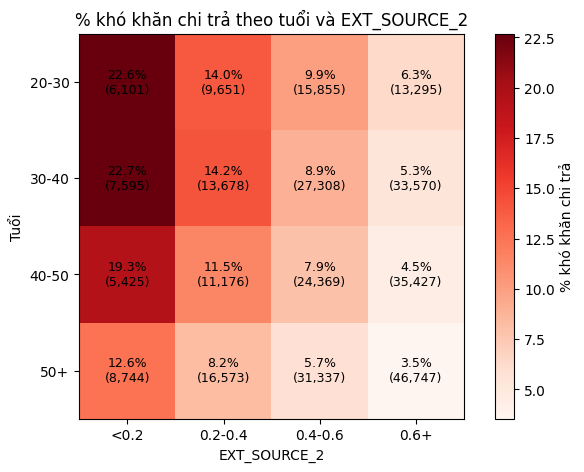

In [46]:
app = app.withColumn('EXT2_GROUP',
    F.when(F.col('EXT_SOURCE_2') < 0.2, '<0.2')
     .when(F.col('EXT_SOURCE_2') < 0.4, '0.2-0.4')
     .when(F.col('EXT_SOURCE_2') < 0.6, '0.4-0.6')
     .otherwise('0.6+'))

rows = (app.filter(F.col('EXT_SOURCE_2').isNotNull())
           .groupBy('AGE_GROUP', 'EXT2_GROUP')
           .agg(F.count('*').alias('n'), F.avg('TARGET').alias('rate'))
           .collect())

cell = {}
for r in rows:
    cell[(r['AGE_GROUP'], r['EXT2_GROUP'])] = (r['rate'] * 100, r['n'])

age_groups = ['20-30', '30-40', '40-50', '50+']
ext_groups = ['<0.2', '0.2-0.4', '0.4-0.6', '0.6+']

matrix = []
for a in age_groups:
    line = []
    for e in ext_groups:
        if (a, e) in cell:
            line.append(cell[(a, e)][0])
        else:
            line.append(float('nan'))
    matrix.append(line)

plt.figure(figsize=(8, 5))
plt.imshow(matrix, cmap='Reds')
plt.colorbar(label='% khó khăn chi trả')

for i, a in enumerate(age_groups):
    for j, e in enumerate(ext_groups):
        if (a, e) in cell:
            rate, n = cell[(a, e)]
            plt.text(j, i, f'{rate:.1f}%\n({n:,})', ha='center', va='center', fontsize=9)

plt.xticks(range(len(ext_groups)), ext_groups)
plt.yticks(range(len(age_groups)), age_groups)
plt.xlabel('EXT_SOURCE_2')
plt.ylabel('Tuổi')
plt.title('% khó khăn chi trả theo tuổi và EXT_SOURCE_2')
plt.show()

- Ở mọi nhóm tuổi, điểm càng cao rủi ro càng giảm mạnh. Ví dụ khách 20–30 tuổi: điểm dưới 0.2 thì cứ 100 người có 22.6 người gặp khó khăn chi trả, điểm trên 0.6 chỉ còn 6.3 người. Khách trên 50 tuổi cũng giảm từ 12.6% xuống 3.5%. Tức là điểm EXT_SOURCE_2 mang thông tin riêng, không trùng với tuổi.
- Điểm tác động mạnh hơn tuổi nhiều. Cùng tuổi, điểm từ thấp nhất lên cao nhất giảm rủi ro khoảng 3.6 lần. Còn cùng mức điểm, từ trẻ nhất lên lớn tuổi nhất chỉ giảm khoảng 1.8 lần.
- Khách điểm dưới 0.2 là nhóm rủi ro nhất cả bảng: người 20–40 tuổi có điểm thấp có tỷ lệ 22.6–22.7%, gần gấp 3 mức chung 8.07%.

## Danh sách feature – application_train

| Feature | Xử lý | Mức tín hiệu | Lý do (từ EDA) |
|---|---|---|---|
| `EXT_SOURCE_1`, `_2`, `_3` | Giữ nguyên, giữ cả null | Mạnh | Tách 2 nhóm rõ nhất; cùng tuổi vẫn giảm rủi ro 3.6 lần từ điểm thấp lên điểm cao |
| `DAYS_BIRTH` | Đổi ra năm | Vừa | Nhóm khó khăn trẻ hơn (39.1 so với 43.5 tuổi); cộng dồn với thâm niên |
| `DAYS_EMPLOYED` | Đổi ra năm, mã `365243` thành null + cờ riêng | Vừa | Nhóm khó khăn đi làm ngắn hơn (3.4 so với 4.6 năm); thâm niên quan trọng hơn thu nhập |
| `CODE_GENDER` | Bỏ `XNA` (4 đơn) | Vừa | Nam 10.14% so với nữ 7.0%, nam cao hơn ở mọi độ tuổi |
| `NAME_INCOME_TYPE` | Gộp 4 nhóm nhỏ thành `Other` | Vừa | Hưu trí 5.39%, công chức 5.75%, người đi làm 9.59% |
| `NAME_FAMILY_STATUS` | Bỏ `Unknown` (2 đơn) | Vừa | Độc thân, sống chung gần 10%, góa 5.82% |
| `NAME_CONTRACT_TYPE` | Giữ nguyên | Yếu | Xoay vòng 5.48% so với tiền mặt 8.35%, nhưng chỉ 10% đơn là xoay vòng |
| `CNT_CHILDREN` | Giữ nguyên | Yếu | Có con 8.7–10% so với không con 7.71%, chỉ rõ khi thu nhập dưới 200k |
| `AMT_INCOME_TOTAL` | Giữ nguyên | Yếu | Đứng riêng gần như không khác, chỉ có tác dụng khi trên 200k |
| `AMT_CREDIT` | Giữ nguyên | Yếu | Đứng riêng yếu, khoản vay tầm trung 300–800k rủi ro hơn |
| `AMT_ANNUITY` | Giữ nguyên | Yếu | Trung vị gần như bằng nhau |
| `AMT_GOODS_PRICE` | Giữ nguyên | Yếu | Hai nhóm gần như trùng khít |
| `DAYS_REGISTRATION` | Đổi ra năm | Yếu | Chênh lệch nhỏ (11.1 so với 12.4 năm) |

**Tạm bỏ:** 47 cột thông tin tòa nhà.

**Chưa xem, quay lại sau:** học vấn, nghề nghiệp, loại tổ chức, xếp hạng vùng, có nhà / có xe, vòng quen biết, số lần bị tra cứu tín dụng, `FLAG_DOCUMENT_*`, các cột liên lạc, ngoại lai cột tiền.